# 0 · Crime overview — all offence categories in Victoria

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'processed'
FIG = ROOT / 'notebooks' / 'outputs'
FIG.mkdir(exist_ok=True)

offences_lga = pd.read_parquet(DATA / 'offences_lga.parquet')
lga_population = pd.read_parquet(DATA / 'lga_population.parquet')
special_areas = pd.read_parquet(DATA / 'special_areas.parquet')
lga_lookup = pd.read_parquet(DATA / 'lga_lookup.parquet')


**Chart style.** One light theme for every notebook: hairline solid gridlines, muted axes, and each offence division keeps the
same colour in every chart. The six colours are categorical slots 1–6 in a fixed order that was checked for colour-blind
separation; three of them are low-contrast on white, so every chart is paired with a table of its numbers.

In [ ]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS, NEUTRAL = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#f0efec'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica Neue', 'Arial', 'DejaVu Sans'], 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'legend.frameon': False, 'figure.dpi': 110,
})

DIVISION_COLOURS = {
    'A Crimes against the person': '#2a78d6',
    'B Property and deception offences': '#eb6834',
    'C Drug offences': '#1baf7a',
    'D Public order and security offences': '#eda100',
    'E Justice procedures offences': '#e87ba4',
    'F Other offences': '#008300',
}
LOCKDOWN_YEARS = (2020, 2022)   # financial years touched by Melbourne's COVID-19 lockdowns (Mar 2020 – Oct 2021)

thousands = FuncFormatter(lambda x, _: f'{x:,.0f}')


def shade_lockdowns(ax):
    ax.axvspan(LOCKDOWN_YEARS[0] - 0.5, LOCKDOWN_YEARS[1] + 0.5, color=NEUTRAL, zorder=0, linewidth=0)
    ax.text(sum(LOCKDOWN_YEARS) / 2, 0.98, 'COVID-19 lockdown years', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=8, color=MUTED)


def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')


## 1. Statewide offences and rate, 2017–2026

Counts are the sum of Table 02 over all 79 LGAs. This leaves out the small number of offences recorded at justice institutions
and in unincorporated Victoria (no resident population; share printed below), so every count has a matching population.

Victoria's population grew about 14% over the decade, so raw counts drift up even if crime does not.
The **rate per 100,000 population** removes that effect and is the measure to compare years with.

In [ ]:
state = (offences_lga.groupby('year')['offences'].sum().to_frame()
         .join(lga_population.groupby('year')['population'].sum()))
state['rate_per_100k'] = state['offences'] / state['population'] * 1e5
state['offences_change_%'] = state['offences'].pct_change() * 100
state['rate_change_%'] = state['rate_per_100k'].pct_change() * 100

excluded = special_areas.groupby('year')['offences'].sum()
print(f'Left out (justice institutions + unincorporated): {(excluded / (state["offences"] + excluded)).max():.2%} of offences at most')
state.round(1)


Left out (justice institutions + unincorporated): 0.59% of offences at most


,offences,population,rate_per_100k,offences_change_%,rate_change_%
year,,,,,
2017,529764,6301707,8406.7,NaN,NaN
2018,502954,6422127,7831.6,-5.1,-6.8
2019,510352,6536387,7807.9,1.5,-0.3
2020,540836,6614112,8177.0,6.0,4.7
2021,518400,6546876,7918.3,-4.1,-3.2
2022,467083,6614291,7061.7,-9.9,-10.8
2023,503460,6796235,7407.9,7.8,4.9
2024,549842,6950016,7911.4,9.2,6.8
2025,634156,7072942,8965.9,15.3,13.3


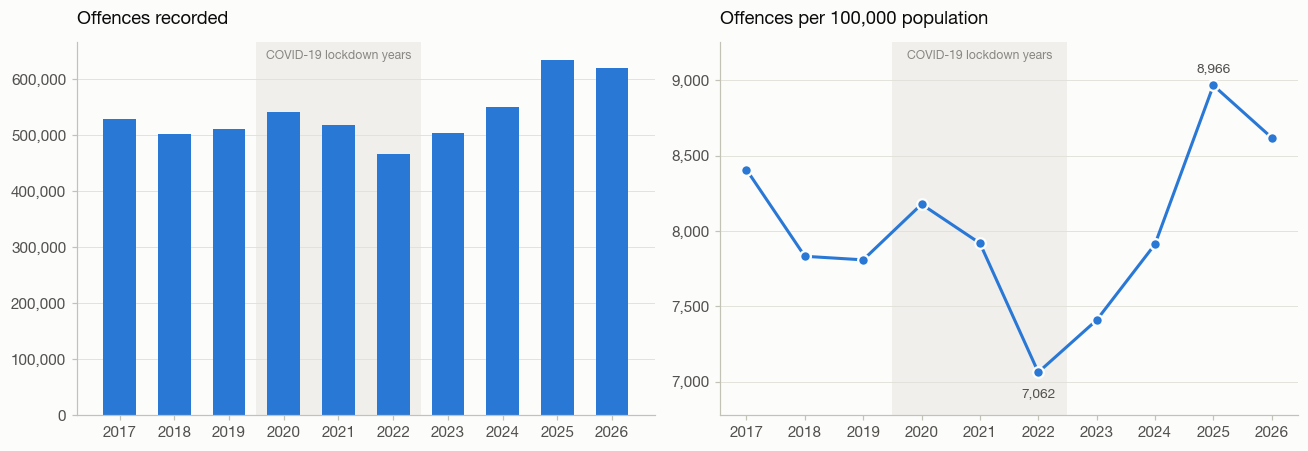

In [ ]:
years = state.index
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.bar(years, state['offences'], width=0.6, color=DIVISION_COLOURS['A Crimes against the person'])
ax1.set_title('Offences recorded')

ax2.plot(years, state['rate_per_100k'], color=DIVISION_COLOURS['A Crimes against the person'], linewidth=2,
         marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax2.set_title('Offences per 100,000 population')
for year, offset in [(state['rate_per_100k'].idxmin(), -16), (state['rate_per_100k'].idxmax(), 9)]:
    ax2.annotate(f"{state.loc[year, 'rate_per_100k']:,.0f}", (year, state.loc[year, 'rate_per_100k']),
                 textcoords='offset points', xytext=(0, offset), ha='center', fontsize=9, color=INK_2)
ax2.margins(y=0.15)

for ax in (ax1, ax2):
    shade_lockdowns(ax)
    ax.set_xticks(years)
    ax.yaxis.set_major_formatter(thousands)

fig.tight_layout()
save(fig, '01_s1_statewide_trend')
plt.show()


**Findings — section 1**

* **Counts and rate tell different stories.** Offences rose 17% (529,764 → 620,155), but population grew 14%, so the rate
  per 100,000 is up only 2.5% (8,407 → 8,619).
* **The decade low came at the end of the lockdowns.** The rate fell to 7,062 in 2022, down 10.8% in a single year.
* **Then three years of rebound.** It peaked at 8,966 in 2025 (+13.3% that year alone, the decade high) and eased 3.9% in 2026.
* The 2020 bump happened while overall activity was falling. Section 2 shows it came from drug offences and *F Other offences*
  (COVID public-health breaches, checked in section 4), not from traditional crime.

## 2. Offence divisions

CSA classifies every offence in a three-level hierarchy: **6 divisions → 28 subdivisions → 112 subgroups**.
This section stays at the top level; section 3 will go down to subgroups.

### 2.1 Size and growth of each division

In [ ]:
div_counts = offences_lga.pivot_table(index='division', columns='year', values='offences', aggfunc='sum')
div_rates = div_counts.div(state['population'], axis=1) * 1e5
first, latest = div_counts.columns.min(), div_counts.columns.max()

division_summary = pd.DataFrame({
    f'offences {latest}': div_counts[latest],
    f'share {latest} %': div_counts[latest] / div_counts[latest].sum() * 100,
    f'rate per 100k {latest}': div_rates[latest],
    f'rate change {first}–{latest} %': (div_rates[latest] / div_rates[first] - 1) * 100,
}).round(1)
division_summary


,offences 2026,share 2026 %,rate per 100k 2026,rate change 2017–2026 %
division,,,,
A Crimes against the person,95322,15.4,1324.7,6.9
B Property and deception offences,357246,57.6,4964.8,-0.7
C Drug offences,34583,5.6,480.6,0.6
D Public order and security offences,31083,5.0,432.0,-24.1
E Justice procedures offences,100463,16.2,1396.2,27.0
F Other offences,1458,0.2,20.3,-15.6


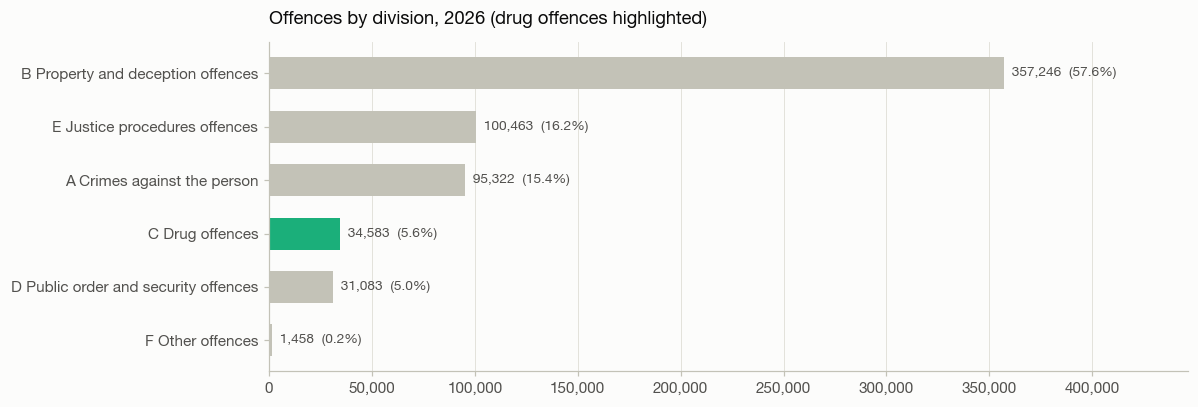

In [ ]:
s = div_counts[latest].sort_values()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.barh(s.index, s.values, height=0.6,
        color=[DIVISION_COLOURS[d] if d.startswith('C') else AXIS for d in s.index])
for i, value in enumerate(s.values):
    ax.text(value, i, f'  {value:,.0f}  ({value / s.sum():.1%})', va='center', fontsize=9, color=INK_2)
ax.set_title(f'Offences by division, {latest} (drug offences highlighted)')
ax.set_xlim(0, s.max() * 1.25)
ax.xaxis.set_major_formatter(thousands)
ax.grid(False)
ax.xaxis.grid(True)
fig.tight_layout()
save(fig, '01_s2_divisions_latest')
plt.show()


### 2.2 Share of offences by division over time

In [ ]:
share = div_counts.div(div_counts.sum(axis=0), axis=1) * 100
share.round(1)


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
division,,,,,,,,,,
A Crimes against the person,14.7,15.7,15.7,15.2,16.3,17.4,16.6,16.0,15.2,15.4
B Property and deception offences,59.4,57.2,56.2,56.2,48.5,50.5,54.1,56.7,59.4,57.6
C Drug offences,5.7,5.9,6.3,6.8,7.1,6.4,6.0,5.7,5.1,5.6
D Public order and security offences,6.8,6.9,6.8,5.8,5.7,6.1,5.8,5.1,4.7,5.0
E Justice procedures offences,13.1,13.9,14.7,14.7,16.0,17.2,17.3,16.2,15.3,16.2
F Other offences,0.3,0.4,0.3,1.4,6.4,2.4,0.2,0.3,0.3,0.2


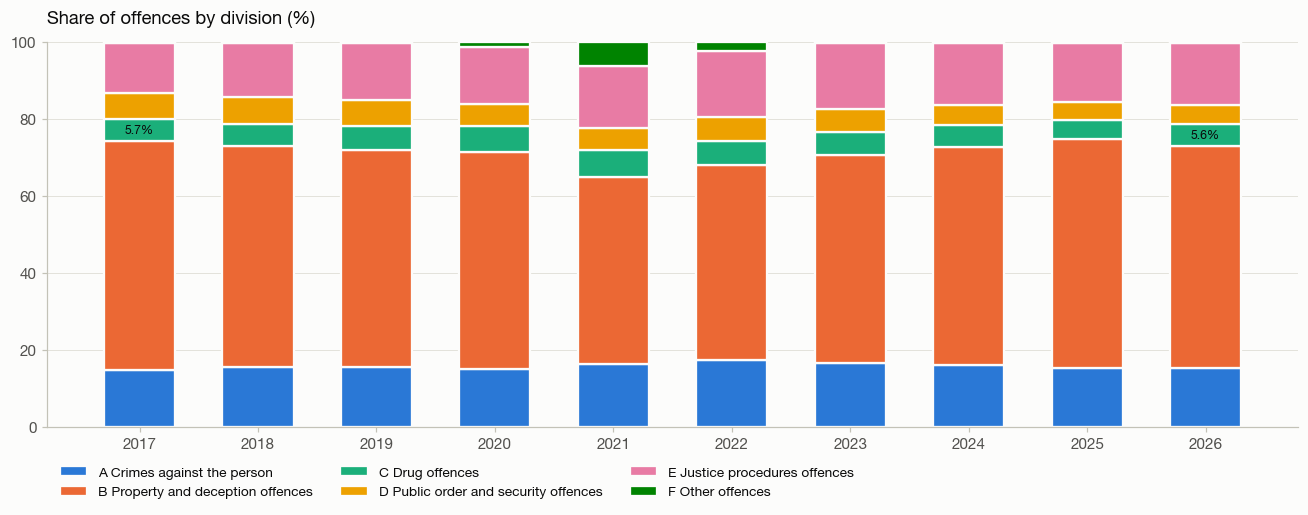

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.8))
bottom = pd.Series(0.0, index=share.columns)
for division in share.index:
    ax.bar(share.columns, share.loc[division], bottom=bottom, width=0.6, label=division,
           color=DIVISION_COLOURS[division], edgecolor=SURFACE, linewidth=1.5)
    if division.startswith('C'):
        for year in (first, latest):
            ax.text(year, bottom[year] + share.loc[division, year] / 2, f'{share.loc[division, year]:.1f}%',
                    ha='center', va='center', fontsize=8, color=INK)
    bottom += share.loc[division]

ax.set_title('Share of offences by division (%)')
ax.set_ylim(0, 100)
ax.set_xticks(share.columns)
ax.legend(ncol=3, loc='upper left', bbox_to_anchor=(0, -0.07), fontsize=9)
fig.tight_layout()
save(fig, '01_s2_division_share')
plt.show()


### 2.3 Which divisions grew fastest?

Growth is measured on the **rate per 100,000** (so population growth is removed) and indexed to 2017 = 100.
*F Other offences* is left off this chart: it is usually ~0.3% of offences but jumps ~20-fold to 6% in 2021, which would flatten every
other line. Section 4 looks at that spike.

In [ ]:
index = div_rates.div(div_rates[first], axis=0) * 100
index.round(1)


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
division,,,,,,,,,,
A Crimes against the person,100.0,99.0,98.8,100.0,104.0,99.3,99.0,102.4,110.2,106.9
B Property and deception offences,100.0,89.7,87.8,91.9,76.9,71.4,80.2,89.8,106.6,99.3
C Drug offences,100.0,96.6,103.0,115.9,117.0,94.7,92.8,94.5,95.9,100.6
D Public order and security offences,100.0,94.7,93.4,83.7,79.7,75.8,75.7,70.4,74.0,75.9
E Justice procedures offences,100.0,99.3,104.6,109.5,115.2,110.4,116.3,116.3,124.6,127.0
F Other offences,100.0,129.9,83.0,465.9,2111.4,697.6,76.9,109.5,94.0,84.4


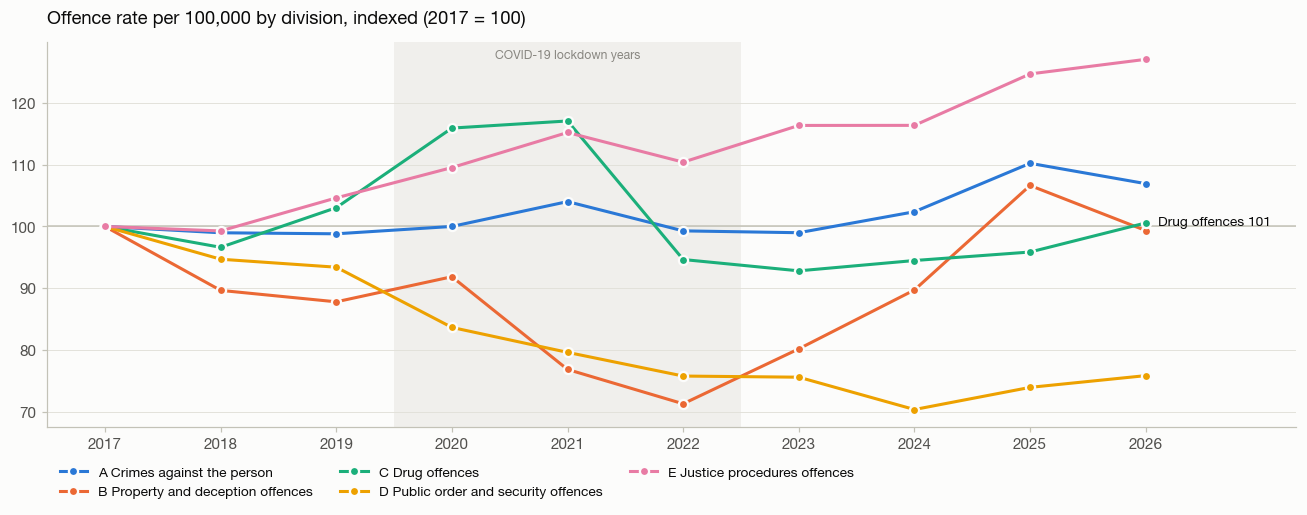

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.8))
shade_lockdowns(ax)
ax.axhline(100, color=AXIS, linewidth=1)
for division in index.index.drop('F Other offences'):
    ax.plot(index.columns, index.loc[division], color=DIVISION_COLOURS[division], linewidth=2, label=division,
            marker='o', markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)

drug = index.loc['C Drug offences']
ax.annotate(f'Drug offences {drug[latest]:.0f}', (latest, drug[latest]), textcoords='offset points', xytext=(8, 0),
            va='center', fontsize=9, color=INK)
ax.set_title(f'Offence rate per 100,000 by division, indexed ({first} = 100)')
ax.set_xticks(index.columns)
ax.set_xlim(first - 0.5, latest + 1.3)
ax.legend(ncol=3, loc='upper left', bbox_to_anchor=(0, -0.07), fontsize=9)
fig.tight_layout()
save(fig, '01_s2_division_index')
plt.show()


**Findings — section 2**

* **Property and deception offences dominate:** 57.6% of all offences in 2026. Justice procedures (16.2%) and crimes
  against the person (15.4%) follow. **Drug offences are 5.6%, about 1 in 18 offences** (34,583).
* **Drug offences move against the overall trend.** In 2020–21, the property crime rate fell by up to 29% (lowest in 2022), but the drug offence rate *rose*
  to 117 (2017 = 100), lifting the drug share to a peak of 7.1% in 2021. One plausible reason is more police stops on
  near-empty streets during lockdowns. That's a hypothesis: these yearly totals can't prove it.
* **Drug offences fell sharply after lockdowns** (index 117 → 95 in 2022) and have climbed back to the 2017 level (101) by 2026.
* **Long-run per-capita change, 2017–2026:** justice procedures +27% (mostly breaches of orders), crimes against the person +7%,
  drugs +1%, property −1%, public order −24%.

**Why this matters for RQ1:** drug offences behave like an **enforcement-driven** measure, not a mirror of general crime.
Notebook 02 has to read every drug hotspot as "where police record drug offences", which is partly where drugs are used or
supplied and partly where police look.

## 3. Offence subdivisions — which crimes are recorded most?

In [ ]:
sub_year = offences_lga.pivot_table(index=['division', 'subdivision'], columns='year', values='offences', aggfunc='sum')
rate = sub_year.div(state['population'], axis=1) * 1e5
TOTAL = f'offences {first}–{latest}'

subdivisions = pd.DataFrame({
    TOTAL: sub_year.sum(axis=1),
    'share %': sub_year.sum(axis=1) / sub_year.values.sum() * 100,
    f'offences {latest}': sub_year[latest],
    f'rate per 100k {latest}': rate[latest],
    f'rate change {first}–{latest} %': (rate[latest] / rate[first] - 1) * 100,
}).sort_values(TOTAL, ascending=False).round(1)
subdivisions


offences 2017–2026  share %  offences 2026  rate per 100k 2026  rate change 2017–2026 %
division                             subdivision                                                                                                                                
B Property and deception offences    B40 Theft                                                      1821161     33.9         234654              3261.1                     13.2
E Justice procedures offences        E20 Breaches of orders                                          702293     13.1          85922              1194.1                     32.7
A Crimes against the person          A20 Assault and related offences                                462351      8.6          52059               723.5                      7.4
B Property and deception offences    B20 Property damage                                             419984      7.8          46936               652.3                     -2.7
                                     B30 Burglary/Break and enter                                    404506      7.5          39862               554.0                    -32.9
                                     B50 Deception                                                   324356      6.0          32104               446.2                    -21.7
C Drug offences                      C30 Drug use and possession                                     261403      4.9          28695               398.8                      4.3
D Public order and security offences D10 Weapons and explosives offences                             159712      3.0          17772               247.0                     -2.1
A Crimes against the person          A30 Sexual offences                                             148247      2.8          17293               240.3                     13.1
                                     A70 Stalking, harassment and threatening behaviour              131189      2.4          14957               207.9                     11.3
E Justice procedures offences        E10 Justice procedures                                          128251      2.4          14541               202.1                      1.3
D Public order and security offences D20 Disorderly and offensive conduct                            109017      2.0           7446               103.5                    -60.4
A Crimes against the person          A80 Dangerous and negligent acts endangering pe...               61451      1.1           6516                90.6                     -6.0
F Other offences                     F90 Miscellaneous offences                                       52462      1.0            392                 5.4                     11.8
C Drug offences                      C10 Drug dealing and trafficking                                 42479      0.8           3566                49.6                    -30.6
D Public order and security offences D30 Public nuisance offences                                     42210      0.8           5570                77.4                     43.1
A Crimes against the person          A50 Robbery                                                      31425      0.6           2930                40.7                    -19.5
B Property and deception offences    B10 Arson                                                        29114      0.5           3621                50.3                     -2.5
C Drug offences                      C20 Cultivate or manufacture drugs                               18889      0.4           2302                32.0                     34.2
A Crimes against the person          A40 Abduction and related offences                                7346      0.1            750                10.4                    -13.0
F Other offences                     F20 Transport regulation offences                                 4981      0.1            485                 6.7                    -38.8
                  

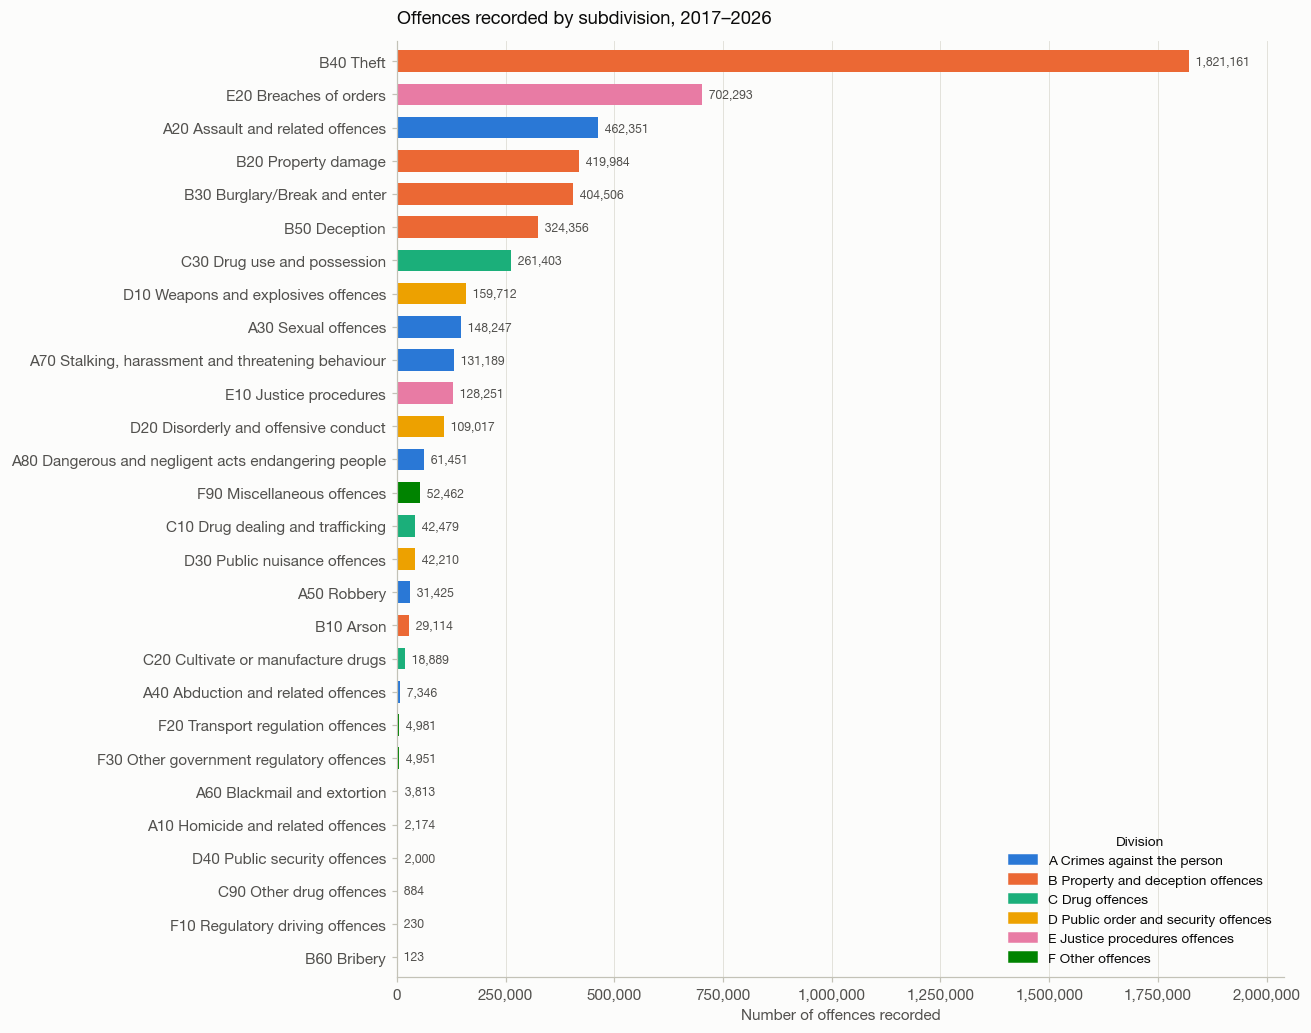

In [ ]:
ranked = subdivisions[TOTAL].sort_values()
fig, ax = plt.subplots(figsize=(12, 9.5))
ax.barh(ranked.index.get_level_values('subdivision'), ranked.values, height=0.65,
        color=[DIVISION_COLOURS[d] for d in ranked.index.get_level_values('division')])
for i, value in enumerate(ranked.values):
    ax.text(value, i, f'  {value:,.0f}', va='center', fontsize=8, color=INK_2)

ax.set_title(f'Offences recorded by subdivision, {first}–{latest}')
ax.set_xlabel('Number of offences recorded')
ax.set_xlim(0, ranked.max() * 1.12)
ax.set_ylim(-0.6, len(ranked) - 0.4)
ax.xaxis.set_major_formatter(thousands)
ax.grid(False)
ax.xaxis.grid(True)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in DIVISION_COLOURS.values()], DIVISION_COLOURS.keys(),
          title='Division', loc='lower right', fontsize=9, title_fontsize=9)
fig.tight_layout()
save(fig, '01_s3_subdivisions')
plt.show()


**Findings — section 3**

* **Theft is in a league of its own:** 1.82 million offences, 34% of everything recorded. That is more than the next three
  subdivisions combined (breaches of orders, assault, property damage). The top six subdivisions make up 77% of all offences.
* **C30 Drug use and possession is the 7th-largest subdivision** (261,403; 4.9%), bigger than weapons or sexual offences.
  **Within drug offences, 81% are use/possession**, 13% dealing/trafficking (C10), 6% cultivate/manufacture (C20).
* **The drug subdivisions are moving in different directions** (rate per 100k, 2017–2026):
  * Use/possession is steady (+4%).
  * Dealing/trafficking is down 31%.
  * Cultivate/manufacture is up 34%, but that rise is entirely **C23 possessing equipment or precursors** (585 → 1,752 a year).
    Actual cultivation (C21) *fell* from 917 to 549. Notebook 02 should keep C21 and C23 apart.
* **Law changes show up in the data.** D20 Disorderly conduct fell 60%. Nearly all of that drop is *D22 Drunk and disorderly in
  public* (8,053 → 23), which follows Victoria decriminalising public drunkenness in November 2023. Policy, not behaviour.
  The same caution applies to drug offence trends.
* **Fastest-growing large subdivision:** E20 Breaches of orders (+33% per capita), driven by breaches of family violence orders
  (38,500 → 60,938 a year).

## 4. Top crime types by region — percentile slice and cluster maps

With 112 offence subgroups and 79 LGAs, a full table is too big to read. Two reductions:

* **Crime types:** keep only the subgroups whose statewide total is above a
  percentile (here the **75th: the top quarter**).
* **Areas:** group the 79 LGAs into the Victorian Government's **15 partnership regions** (6 metropolitan, 9 regional; built in
  notebook 00)

Hierarchical clustering then reorders both axes so similar regions and similar crime types sit next to each other. Crime types
are rows and regions are columns. Three views:

| View | Scaling | Question it answers |
|---|---|---|
| 4.1 | raw counts | Where are the most offences? (mostly population size) |
| 4.2 | each **region** (column) scaled 0–1 | What is each region's crime *mix*? |
| 4.3 | each **crime type** (row) scaled 0–1, on **rate per 100k** | Where is each crime type most concentrated? |

In [ ]:
PER = 75


def top_types_by_area(df, per, area='region'):
    table = (df.merge(lga_lookup[['lga', area]], on='lga')
             .pivot_table(index='subgroup', columns=area, values='offences', aggfunc='sum', fill_value=0))
    totals = table.sum(axis=1)
    keep = totals[totals > totals.quantile(per / 100)].sort_values(ascending=False).index
    return table.loc[keep]


top_counts = top_types_by_area(offences_lga, PER)
person_years = lga_population.merge(lga_lookup[['lga', 'region']], on='lga').groupby('region')['population'].sum()
top_rates = top_counts.div(person_years, axis=1) * 1e5   # average offences per 100,000 residents per year, 2017–2026

print(f'{len(top_counts)} of {offences_lga["subgroup"].nunique()} subgroups kept, '
      f'covering {top_counts.values.sum() / offences_lga["offences"].sum():.0%} of all offences')
top_rates.round(0).astype(int)


28 of 112 subgroups kept, covering 90% of all offences


region,Barwon,Central Highlands,Eastern Metro,Gippsland,Goulburn,Great South Coast,Inner Metro,Inner South-east Metro,Loddon Campaspe,Mallee,Northern Metro,Ovens Murray,Southern Metro,Western Metro,Wimmera Southern Mallee
subgroup,,,,,,,,,,,,,,,
B42 Steal from a motor vehicle,756,931,786,627,561,318,1789,1032,592,658,995,436,890,1000,288
E21 Breach family violence order,838,913,466,1661,1750,906,642,314,1056,1494,634,918,794,628,1567
B49 Other theft,654,774,463,722,733,551,1931,517,671,808,678,560,615,799,762
B21 Criminal damage,654,691,360,932,783,699,958,370,639,957,510,643,551,520,837
B53 Obtain benefit by deception,374,239,337,335,326,307,1397,386,266,448,403,312,361,334,343
B43 Steal from a retail store,433,384,347,436,351,289,1033,375,371,444,360,223,382,371,223
C32 Drug possession,338,278,293,489,494,418,942,236,310,639,342,389,404,321,545
B321 Residential non-aggravated burglary,342,366,283,386,363,255,524,374,285,425,326,224,288,298,297
B41 Motor vehicle theft,258,411,240,258,289,137,605,275,258,340,380,164,321,346,142


In [ ]:
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])
AREA_COLOURS = {'Metropolitan': INK_2, 'Regional': GRID}


def short(label, n=40):
    return label if len(label) <= n else label[:n - 1] + '…'


row_colours = (offences_lga[['subgroup', 'division']].drop_duplicates().set_index('subgroup')['division']
               .map(DIVISION_COLOURS).rename(index=short).rename('Division'))
col_colours = (lga_lookup.drop_duplicates('region').set_index('region')['area_type']
               .map(AREA_COLOURS).rename('Metro / regional'))
legend_handles = ([Patch(color=c, label=a) for a, c in AREA_COLOURS.items()]
                  + [Patch(color=c, label=d) for d, c in DIVISION_COLOURS.items()])


def area_clustermap(table, title, name, **kwargs):
    g = sns.clustermap(table.rename(index=short), cmap=BLUES, figsize=(13, 12), linewidths=1, linecolor=SURFACE,
                       row_colors=row_colours, col_colors=col_colours, yticklabels=True, xticklabels=True,
                       dendrogram_ratio=(0.1, 0.1), colors_ratio=(0.012, 0.015), cbar_pos=(0.02, 0.83, 0.015, 0.08),
                       **kwargs)
    g.ax_heatmap.set_xlabel('')
    g.ax_heatmap.set_ylabel('')
    g.ax_heatmap.tick_params(axis='both', labelsize=9, length=0)
    g.ax_row_colors.tick_params(bottom=False, labelbottom=False)   # legend already names the strip
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=40, ha='right', rotation_mode='anchor')
    g.figure.suptitle(title, x=0.02, y=1.06, ha='left', fontsize=14, fontweight='bold')
    g.figure.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(0.02, 1.045), ncol=4, fontsize=8)
    g.savefig(FIG / f'{name}.png', dpi=130, bbox_inches='tight')
    plt.show()
    return g


### 4.1 Raw counts (no scaling)

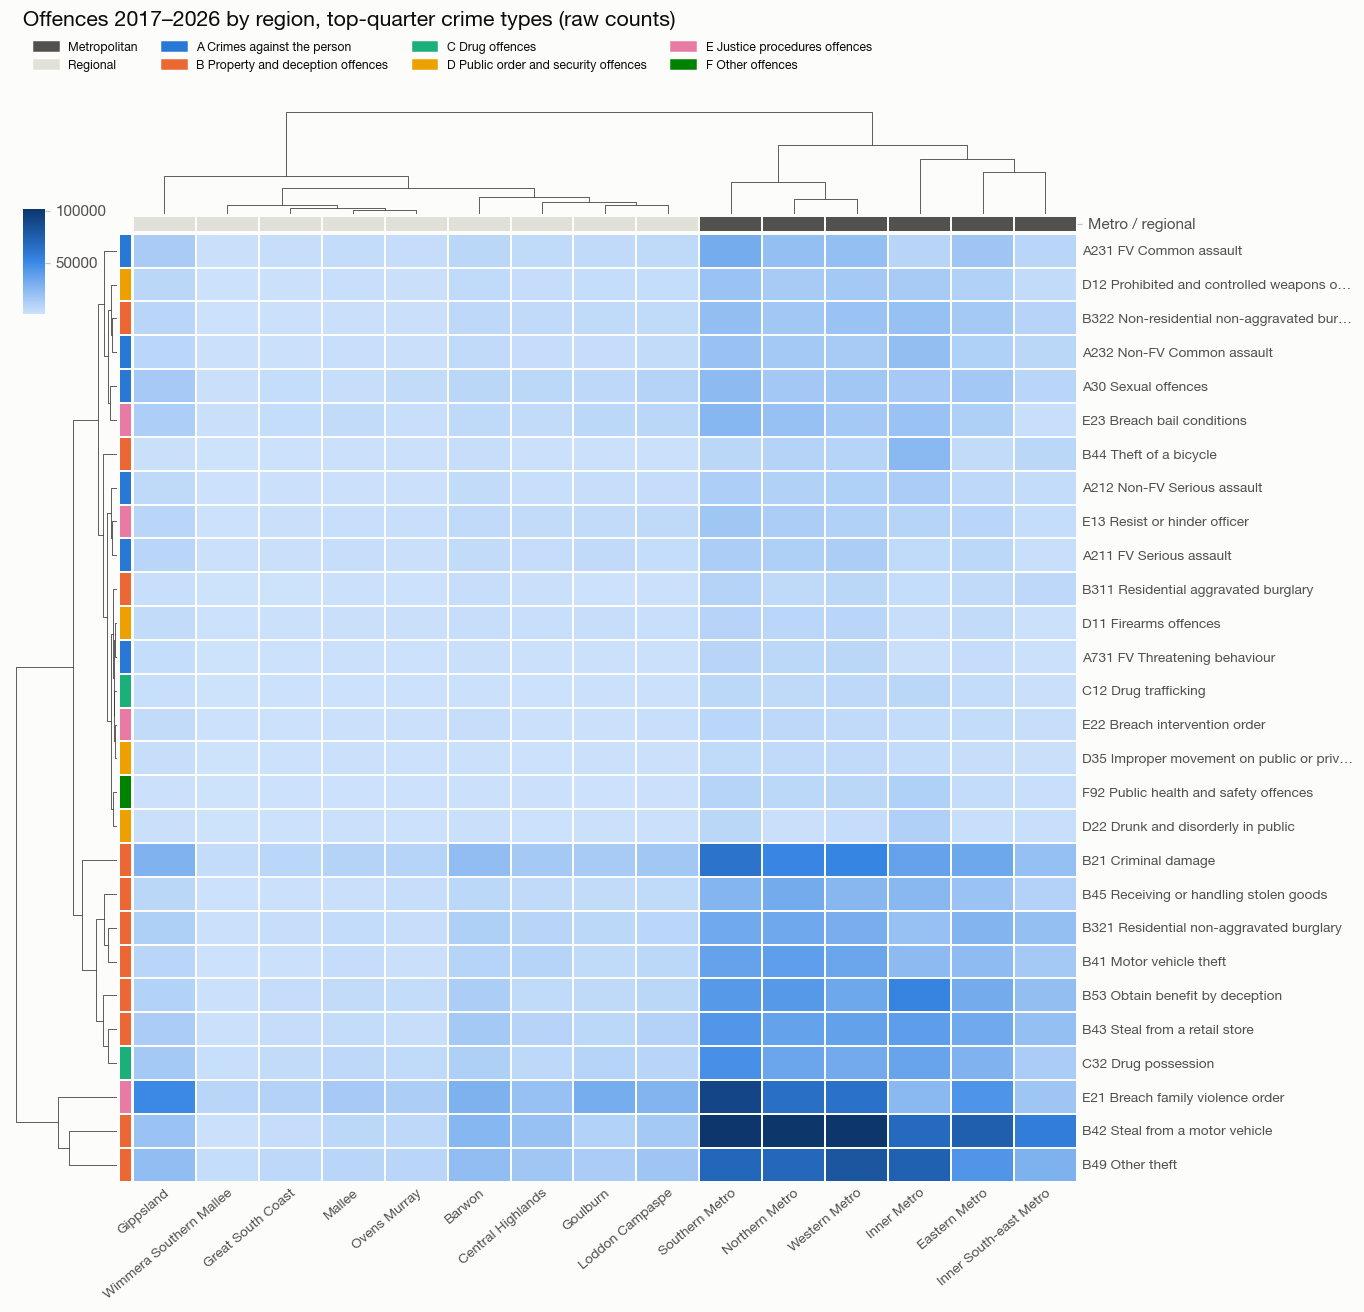

In [ ]:
g_counts = area_clustermap(top_counts, 'Offences 2017–2026 by region, top-quarter crime types (raw counts)',
                           '01_s4_cluster_counts')


### 4.2 Scaled within each region: the crime mix

Each column is rescaled so that the region's most common crime type = 1. Columns that look alike have similar crime
profiles, whatever their size.

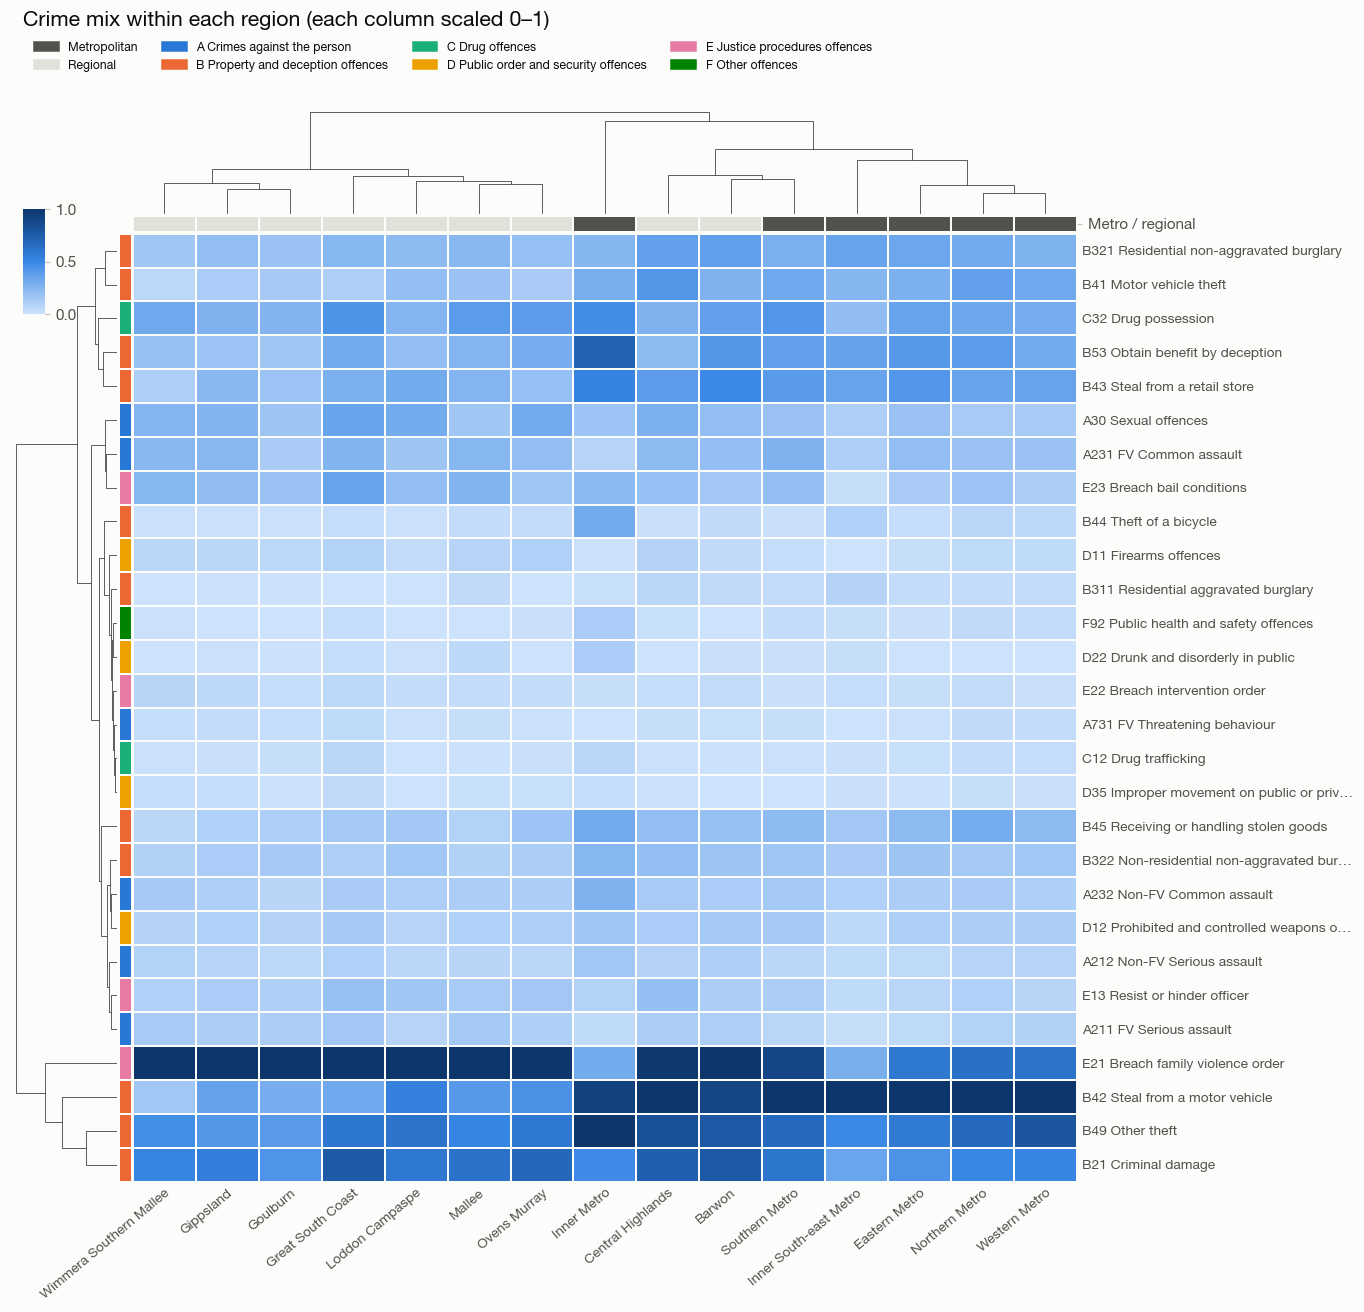

In [ ]:
g_mix = area_clustermap(top_counts, 'Crime mix within each region (each column scaled 0–1)', '01_s4_cluster_mix',
                        standard_scale=1)


### 4.3 Scaled within each crime type: where is it concentrated? (rate per 100k)

Each row is rescaled so that the region with the highest rate = 1. Dark cells mark where a crime type is most concentrated per
resident. Caveat: *Inner Metro* contains the City of Melbourne, with a small resident population but a huge daytime population
(workers, visitors, nightlife), so its per-resident rates are inflated.

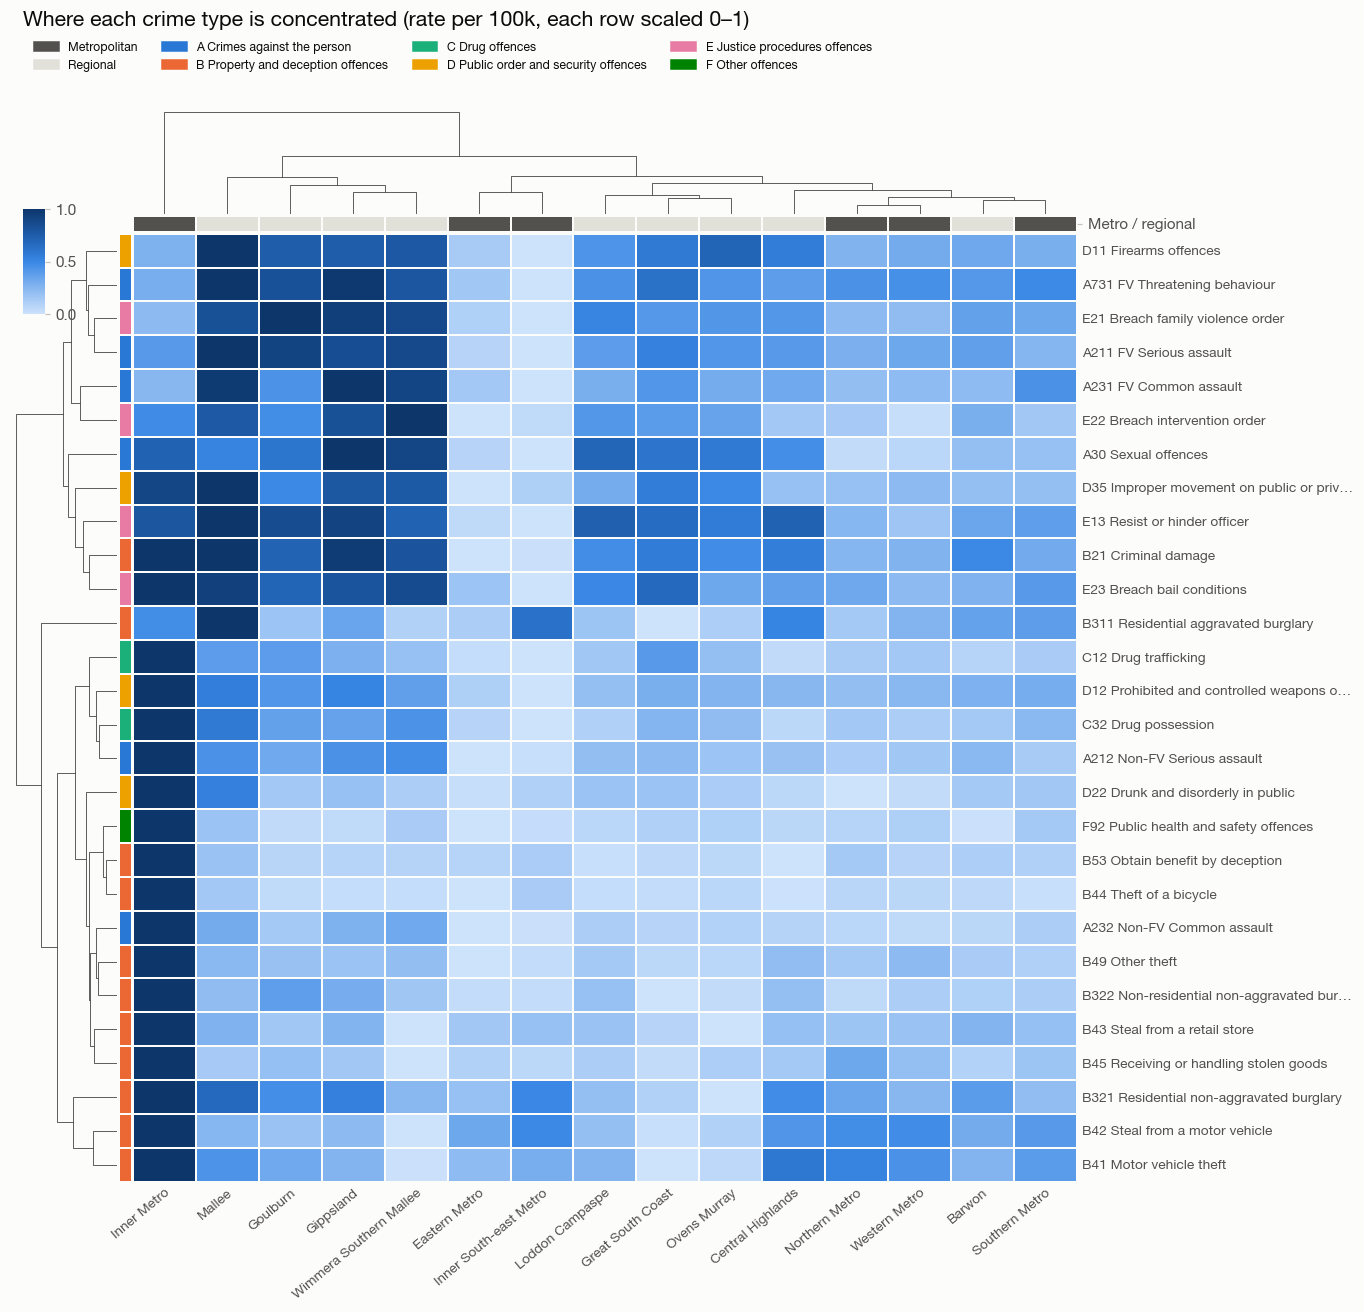

In [ ]:
g_where = area_clustermap(top_rates, 'Where each crime type is concentrated (rate per 100k, each row scaled 0–1)',
                          '01_s4_cluster_where', standard_scale=0)


**Findings — section 4**

**4.1 Raw counts mostly track population.** The big metro regions (Southern, Western, Northern) lead on almost every row.
Useful for scale, not for comparison.

**4.2 Crime mix: the clearest split is metro vs regional.**
* *Steal from a motor vehicle* (B42) is the #1 crime type in **5 of 6 metro regions** and in Central Highlands (Ballarat).
* *Breach of a family violence order* (E21) is #1 in **8 of 9 regional regions**.
* **Inner Metro has its own profile:** led by *other theft*, deception and retail theft.
* Central Highlands and Barwon (Ballarat, Geelong) cluster with the metro regions: the big regional cities look
  metropolitan in their crime mix.

**4.3 Where crime concentrates per resident: three groups.**
1. **Inner Metro is Victoria's "Tenderloin".**
   * It has the highest rate in **18 of the 28 crime types** and 2.1× the state rate across them.
   * **Drug possession** is 942 per 100k (2.5× the state rate of 383); **drug trafficking** is 180 (2.9× the state rate of 62).
   * Its daytime population inflates per-resident rates (see caveat above).
2. **Four rural regions — Mallee, Gippsland, Goulburn, Wimmera Southern Mallee — lead the other 10 types.**
   * These are family violence, firearms, sexual offences, criminal damage, bail breaches and resisting police.
   * Family-violence offences run at 2,330–2,470 per 100k a year there, vs 516 in Inner South-east Metro (about 4.7×).
3. **Everyone else is near or below the state rate.** Eastern Metro (0.72×) and Inner South-east Metro (0.75×) are the
   lowest-crime regions, pale on nearly every row.

**Drug offences in particular: after Inner Metro, the next-highest rates are all regional.**
* **Possession:** Mallee 639, Wimmera Southern Mallee 545, Goulburn 494, Gippsland 489.
* **Trafficking:** Great South Coast 94, Mallee 93, Goulburn 92 (about 1.5× the state rate).
* Every metro region except Inner Metro is *below* the state rate for trafficking.